**Universidad Nacional del Centro del Perú**
**Facultad de Ingeniería de Sistemas**

# Ingeniería del Conocimiento (ISO56B) — Evaluación Parcial 2026-II
## Actividad 2: CNN para clasificar hojas de banano (Sigatoka, Cordana y sanas)

## SECCIÓN A — Presentación

**1. Curso, semestre y fecha:** Ingeniería del Conocimiento (ISO56B) — 2026-II — 21 de octubre de 2026

**2. Integrantes (nombre y código):**
- Echegoyen Rojas Anahi — 2024200183A
- Espinoza Inga Deysi — 2024200184B
- Paucar Ramirez Ariana — 2024200196A
- Tomás Rivera Andriy — 2024200206k

**3. Dataset:** Banana Leaf Image Dataset for Classification of Sigatoka, Cordana, and Healthy Leaves
- Fuente: https://data.mendeley.com/datasets/hzttvh774g/3 (DOI: 10.17632/hzttvh774g.3)
- Autores: Bryan Bazan, Kelvin Lleins Rojas-Córdova, Jhosep Sánchez-Flores y John C. Santa-María (Mendeley Data, versión 3, septiembre de 2026).
- Justificación: el banano es un cultivo de gran importancia agrícola y económica para el Perú, y la Sigatoka y la Cordana son enfermedades foliares que reducen la producción si no se detectan a tiempo. El dataset contiene **2,354 fotografías reales** tomadas en campo, en condiciones naturales, en cuatro sitios agrícolas de la región San Martín (Calzada y Habana en Moyobamba, Zapatero en Lamas y Shima en Huallaga), por lo que representa un problema real y local.

**4. Problema:** se busca clasificar automáticamente la fotografía de una hoja de banano en una de tres clases: **sigatoka** (995 imágenes), **cordana** (815) o **sanas** (544). Es un problema de clasificación multiclase de imágenes RGB con desbalance moderado de clases. Un modelo confiable permitiría apoyar el diagnóstico temprano en campo a partir de una foto de celular, de modo que el agricultor pueda actuar antes de que la enfermedad se extienda. Para ello se entrenan y comparan una CNN base, una CNN regularizada y distintos optimizadores, y se evalúa el mejor modelo sobre un conjunto de test independiente.

**5. GPU:** el notebook se ejecutó en Google Colab con **Runtime → Change runtime type → T4 GPU**. La verificación se muestra en la siguiente celda.

In [ ]:
import os, random, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_curve, auc, roc_auc_score, accuracy_score)
from sklearn.preprocessing import label_binarize
from sklearn.utils.class_weight import compute_class_weight
from PIL import Image
from IPython.display import display, Markdown

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

# Verificación de GPU
gpus = tf.config.list_physical_devices('GPU')
print('TensorFlow:', tf.__version__)
print('GPUs disponibles:', gpus)
if not gpus:
    print('No se detectó GPU. Activar en Runtime → Change runtime type → T4 GPU')

# Semillas para reproducibilidad
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)   # fija random, numpy y tensorflow a la vez

# Diccionario de resultados
RESULTS = {}

TensorFlow: 2.21.0
GPUs disponibles: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## SECCIÓN B — Carga, Exploración y Preprocesamiento

En esta sección se carga el dataset desde Google Drive, se verifica la integridad de los archivos, se explora la distribución de clases y se preparan los conjuntos de entrenamiento, validación y prueba. El dataset no incluye particiones predefinidas, por lo que se generaron mediante divisiones estratificadas con semilla fija: 20 % de las imágenes para prueba y, del resto, 10 % para validación.

In [ ]:
# Carga del dataset desde Google Drive
import os
import zipfile

# Se monta Google Drive para acceder al dataset (carpeta 'datasets' de 'Mi unidad')
from google.colab import drive
drive.mount('/content/drive')

# Definir la ruta exacta del dataset en Drive y la carpeta de extracción en Colab
COMPRESSED_FILE_PATH = '/content/drive/MyDrive/datasets/Banana Leaf.rar'
EXTRACT_PATH = '/content/banana_dataset'

if os.path.exists(COMPRESSED_FILE_PATH):
    print(f"Detectado archivo comprimido en: {COMPRESSED_FILE_PATH}")

    # Crear directorio destino
    os.makedirs(EXTRACT_PATH, exist_ok=True)

    # Caso ZIP
    if COMPRESSED_FILE_PATH.endswith('.zip'):
        print("Descomprimiendo archivo ZIP...")
        with zipfile.ZipFile(COMPRESSED_FILE_PATH, 'r') as zip_ref:
            zip_ref.extractall(EXTRACT_PATH)
        print("¡Descompresión completada exitosamente!")

    # Caso RAR
    elif COMPRESSED_FILE_PATH.endswith('.rar'):
        print("Descomprimiendo archivo RAR... (Instalando unrar primero)")
        # Instalar utilidad unrar de linux de forma silenciosa
        !apt-get install unrar -y > /dev/null
        # Descomprimir usando comando de consola de linux
        !unrar x "{COMPRESSED_FILE_PATH}" "{EXTRACT_PATH}/" > /dev/null
        print("¡Descompresión completada exitosamente!")

    # Mostrar el contenido de la carpeta para verificar las clases
    print("Estructura de carpetas extraída:")
    print(os.listdir(EXTRACT_PATH))
else:
    print(f"No se encontró el archivo comprimido en '{COMPRESSED_FILE_PATH}'.")
    print("Por favor, verifica que la carpeta 'datasets' esté en 'Mi unidad' y contenga el archivo 'Banana Leaf.rar'.")

Mounted at /content/drive
Detectado archivo comprimido en: /content/drive/MyDrive/datasets/Banana Leaf.rar
Descomprimiendo archivo RAR... (Instalando unrar primero)
¡Descompresión completada exitosamente!
Estructura de carpetas extraída:
['sanas', 'sigatoka', 'cordana']


In [ ]:
# Localizar la carpeta que contiene las clases (el RAR puede traer una carpeta intermedia 'Banana Leaf')
BASE_DIR = None
for root, dirs, files in os.walk(EXTRACT_PATH):
    if {'sigatoka', 'cordana', 'sanas'}.issubset({d.lower() for d in dirs}):
        BASE_DIR = root
        break
assert BASE_DIR is not None, 'No se encontraron las carpetas sigatoka / cordana / sanas dentro de EXTRACT_PATH'
print('Ruta base del dataset:', BASE_DIR)

# Orden fijo de clases (alfabético): el índice numérico de cada clase sale de esta lista
CLASS_NAMES = ['cordana', 'sanas', 'sigatoka']
NUM_CLASSES = len(CLASS_NAMES)
dir_by_lower = {d.lower(): d for d in os.listdir(BASE_DIR) if os.path.isdir(os.path.join(BASE_DIR, d))}

VALID_EXT = ('.jpg', '.jpeg', '.png')
paths, labels, ignored = [], [], []
for idx, cname in enumerate(CLASS_NAMES):
    cdir = os.path.join(BASE_DIR, dir_by_lower[cname])
    for fname in sorted(os.listdir(cdir)):
        fpath = os.path.join(cdir, fname)
        if fname.lower().endswith(VALID_EXT):
            paths.append(fpath)
            labels.append(idx)
        else:
            ignored.append(fpath)
print(f'Archivos de imagen encontrados: {len(paths)} | archivos con formato no esperado (ignorados): {len(ignored)}')

# Verificación de archivos corruptos + resolución / canales de TODAS las imágenes (solo se lee la cabecera)
records, corrupt = [], []
for p, y in zip(paths, labels):
    try:
        with Image.open(p) as im:
            im.verify()                      # detecta archivos truncados o corruptos
        with Image.open(p) as im:
            w, h = im.size
            mode = im.mode
        records.append({'path': p, 'label': y, 'clase': CLASS_NAMES[y], 'ancho': w, 'alto': h, 'modo': mode})
    except Exception as e:
        corrupt.append((p, str(e)))
print(f'Archivos corruptos detectados: {len(corrupt)}')
for p, e in corrupt[:10]:
    print('  -', p, '->', e)

df = pd.DataFrame(records)          # el DataFrame solo contiene imágenes válidas
print('\nImágenes válidas por clase:')
print(df['clase'].value_counts().to_string())

print('\nResolución original (ancho x alto):')
print(df[['ancho', 'alto']].describe().round(1).to_string())
print('\nResoluciones más frecuentes:')
print((df['ancho'].astype(str) + 'x' + df['alto'].astype(str)).value_counts().head(5).to_string())
print('\nModos de color (canales):')
print(df['modo'].value_counts().to_string())
print('\n→ Todas las imágenes se convertirán a RGB (3 canales) y se redimensionarán a un tamaño fijo.')

Ruta base del dataset: /content/banana_dataset
Archivos de imagen encontrados: 2354 | archivos con formato no esperado (ignorados): 0
Archivos corruptos detectados: 0

Imágenes válidas por clase:
clase
sigatoka    995
cordana     815
sanas       544

Resolución original (ancho x alto):
        ancho    alto
count  2354.0  2354.0
mean   3077.8  3309.3
std     928.2  1090.4
min     379.0   285.0
25%    2827.8  3000.0
50%    3072.0  3072.0
75%    4080.0  4096.0
max    8000.0  8000.0

Resoluciones más frecuentes:
3072x4096    1057
4096x3072     526
2250x3000      93
4080x3060      61
2250x1688      52

Modos de color (canales):
modo
RGB    2354

→ Todas las imágenes se convertirán a RGB (3 canales) y se redimensionarán a un tamaño fijo.


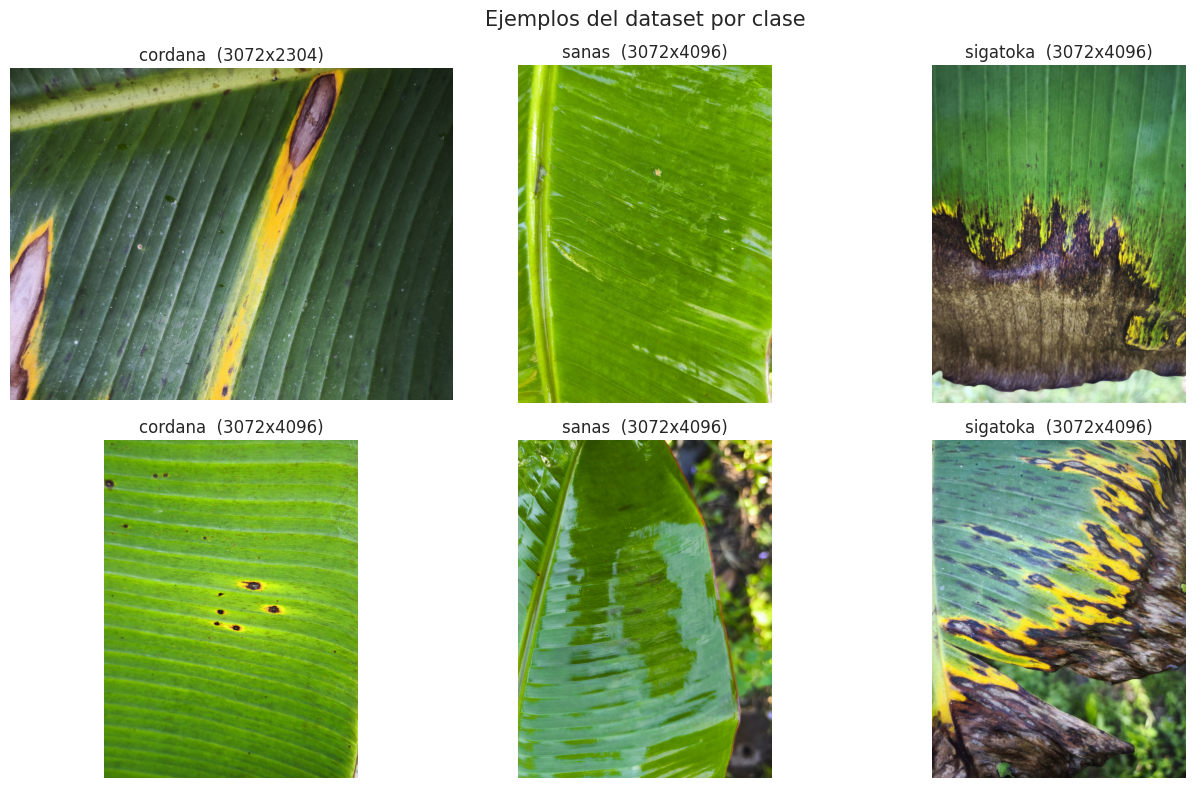

In [ ]:
# Grilla: 2 imágenes por clase (columnas = clases)
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, NUM_CLASSES, figsize=(13, 8))
for j, cname in enumerate(CLASS_NAMES):
    sub = df[df['clase'] == cname]
    for i, row_idx in enumerate(rng.choice(sub.index, size=2, replace=False)):
        r = df.loc[row_idx]
        with Image.open(r['path']) as im:
            axes[i, j].imshow(im.convert('RGB'))
        axes[i, j].set_title(f"{cname}  ({r['ancho']}x{r['alto']})", fontsize=12)
        axes[i, j].axis('off')
plt.suptitle('Ejemplos del dataset por clase', fontsize=15)
plt.tight_layout()
plt.show()

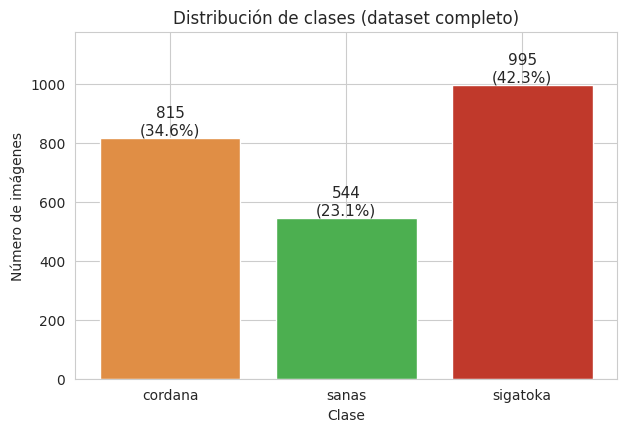

Razón clase mayoritaria / minoritaria: 1.83
→ Desbalance moderado: conviene mirar recall y F1 por clase, no solo el accuracy global.


In [ ]:
counts = df['clase'].value_counts().reindex(CLASS_NAMES)
pct = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(counts.index, counts.values, color=['#e08e45', '#4caf50', '#c0392b'])
for b, c, p in zip(bars, counts.values, pct.values):
    ax.text(b.get_x() + b.get_width() / 2, c + 10, f'{c}\n({p:.1f}%)', ha='center', fontsize=11)
ax.set_title('Distribución de clases (dataset completo)')
ax.set_xlabel('Clase')
ax.set_ylabel('Número de imágenes')
ax.set_ylim(0, counts.max() * 1.18)
plt.show()

ratio = counts.max() / counts.min()
print(f'Razón clase mayoritaria / minoritaria: {ratio:.2f}')
print('→ Desbalance moderado: conviene mirar recall y F1 por clase, no solo el accuracy global.')

In [ ]:
# ---- Parámetros del preprocesamiento ----
IMG_SIZE = 128        # 128x128: las fotos originales son grandes; este tamaño conserva las lesiones
                      # visibles y mantiene bajos el uso de memoria RAM/GPU y el tiempo de entrenamiento
BATCH_SIZE = 32
TEST_SIZE = 0.20      # 20% para test (~471 imágenes): suficientes para estimar métricas por clase,
                      # incluida la clase minoritaria, sin quitarle demasiado a entrenamiento
VAL_SIZE = 0.10       # 10% del train restante (consigna)

paths_all = np.array(df['path'].tolist())
y_all = df['label'].values

# 1) Test estratificado
p_trainval, p_test, y_trainval, y_test = train_test_split(
    paths_all, y_all, test_size=TEST_SIZE, stratify=y_all, random_state=SEED)
# 2) Validación = 10% del train, también estratificada
p_train, p_val, y_train, y_val = train_test_split(
    p_trainval, y_trainval, test_size=VAL_SIZE, stratify=y_trainval, random_state=SEED)

def _load(path):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)   # fuerza RGB (3 canales)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE), antialias=True)     # redimensiona
    return tf.cast(img, tf.float32) / 255.0                              # normaliza a [0, 1]

def load_images(path_array):
    ds = (tf.data.Dataset.from_tensor_slices([str(p) for p in path_array])
          .map(_load, num_parallel_calls=tf.data.AUTOTUNE)
          .batch(64).prefetch(tf.data.AUTOTUNE))
    return np.concatenate([b.numpy() for b in ds], axis=0)               # (N, 128, 128, 3)

CACHE_PATH = f'/content/drive/MyDrive/datasets/cache_banana_{IMG_SIZE}_s{SEED}.npz'   # evita recargar 2354 fotos enormes en cada ejecución
t0 = time.time()
X_train = X_val = X_test = None
if os.path.exists(CACHE_PATH):
    d = np.load(CACHE_PATH)
    if (len(d['X_train']), len(d['X_val']), len(d['X_test'])) == (len(p_train), len(p_val), len(p_test)):
        X_train, X_val, X_test = [d[k].astype(np.float32) / 255.0 for k in ('X_train', 'X_val', 'X_test')]
        print('Imágenes cargadas desde la caché de Drive')
if X_train is None:
    X_train = load_images(p_train)
    X_val = load_images(p_val)
    X_test = load_images(p_test)
    try:
        np.savez(CACHE_PATH, X_train=np.round(X_train * 255).astype(np.uint8),
                 X_val=np.round(X_val * 255).astype(np.uint8), X_test=np.round(X_test * 255).astype(np.uint8))
        print('Caché guardada en Drive')
    except Exception as e:
        print('No se pudo guardar la caché:', e)
print(f'Imágenes listas en {time.time() - t0:.0f} s')
# Las imágenes ya tienen forma (alto, ancho, canales); no hace falta aplanarlas porque la CNN trabaja con 3D.

# Pesos de clase (opcional): se calculan por si se decide compensar el desbalance
cw = compute_class_weight('balanced', classes=np.arange(NUM_CLASSES), y=y_train)
CLASS_WEIGHT = {i: float(w) for i, w in enumerate(cw)}
USE_CLASS_WEIGHT = False   # ponerlo en True para entrenar la CNN mejorada compensando el desbalance
print('class_weight calculado:', {CLASS_NAMES[i]: round(w, 2) for i, w in CLASS_WEIGHT.items()})

Caché guardada en Drive
Imágenes listas en 183 s
class_weight calculado: {'cordana': 0.96, 'sanas': 1.44, 'sigatoka': 0.79}


In [ ]:
print('RESUMEN NUMÉRICO')
print('-' * 50)
print(f'Total imágenes válidas : {len(df)}')
print(f'Train      : {len(X_train):5d}  -> shape {X_train.shape}')
print(f'Validación : {len(X_val):5d}  -> shape {X_val.shape}')
print(f'Test       : {len(X_test):5d}  -> shape {X_test.shape}')
print(f'Rango de píxeles: min={X_train.min():.2f}, max={X_train.max():.2f}  | dtype={X_train.dtype}')

# Proporción de cada clase en cada conjunto (debe ser casi idéntica = estratificación)
tabla = pd.DataFrame({
    'Train': pd.Series(y_train).value_counts(normalize=True).sort_index() * 100,
    'Val':   pd.Series(y_val).value_counts(normalize=True).sort_index() * 100,
    'Test':  pd.Series(y_test).value_counts(normalize=True).sort_index() * 100,
    'Total': pd.Series(y_all).value_counts(normalize=True).sort_index() * 100,
}).round(1)
tabla.index = CLASS_NAMES
print('\nProporción de clases (%) por conjunto:')
display(tabla)

conteos = pd.DataFrame({
    'Train': pd.Series(y_train).value_counts().sort_index(),
    'Val':   pd.Series(y_val).value_counts().sort_index(),
    'Test':  pd.Series(y_test).value_counts().sort_index()})
conteos.index = CLASS_NAMES
print('Número de imágenes por clase y conjunto:')
display(conteos)

RESUMEN NUMÉRICO
--------------------------------------------------
Total imágenes válidas : 2354
Train      :  1694  -> shape (1694, 128, 128, 3)
Validación :   189  -> shape (189, 128, 128, 3)
Test       :   471  -> shape (471, 128, 128, 3)
Rango de píxeles: min=0.00, max=1.00  | dtype=float32

Proporción de clases (%) por conjunto:


,Train,Val,Test,Total
cordana,34.7,34.4,34.6,34.6
sanas,23.1,23.3,23.1,23.1
sigatoka,42.3,42.3,42.3,42.3


Número de imágenes por clase y conjunto:


,Train,Val,Test
cordana,587,65,163
sanas,391,44,109
sigatoka,716,80,199


### Conclusiones de la exploración y decisiones de preprocesamiento

- **Integridad:** se encontraron 2,354 imágenes válidas en formato RGB (3 canales) y ningún archivo corrupto ni con formato inesperado.
- **Resolución:** las fotografías son de gran tamaño y heterogéneas (las más frecuentes son 3072×4096 y 4096×3072 píxeles; el máximo es 8000×8000). Se redimensionaron a **128×128 píxeles**, tamaño que reduce el consumo de memoria y el tiempo de entrenamiento y conserva la información principal de las lesiones.
- **Distribución de clases:** sigatoka 995 (42.3 %), cordana 815 (34.6 %) y sanas 544 (23.1 %). La razón entre la clase mayoritaria y la minoritaria es 1.83, un desbalance moderado. Por ello se utilizan recall y F1 por clase además de la accuracy global, y se estratifican las particiones. No se aplicó `class_weight`.
- **Particiones:** entrenamiento 1,694 imágenes, validación 189 y prueba 471, con proporciones de clase prácticamente idénticas en los tres conjuntos.
- **Normalización:** los píxeles se escalaron al rango [0, 1]. No se requiere reshape adicional, porque las imágenes ya tienen forma (128, 128, 3).

## SECCIÓN C — CNN Base (sin regularización)

Se diseñó una red convolucional base con tres bloques (Conv2D de 32, 64 y 128 filtros, kernel 3×3, `padding='same'` y activación ReLU, cada uno seguido de MaxPooling2D), una capa Flatten, una capa Dense de 128 unidades y una capa de salida softmax de 3 neuronas. Se compiló con el optimizador Adam y la función de pérdida `sparse_categorical_crossentropy`, y se entrenó durante 20 épocas con lotes de 32 imágenes. El parámetro `padding='same'` conserva el tamaño espacial de los mapas de características antes del pooling y evita perder información en los bordes de la imagen.

In [ ]:
def build_cnn_base():
    model = keras.Sequential([
        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        # Bloque 1
        layers.Conv2D(32, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(),
        # Bloque 2
        layers.Conv2D(64, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(),
        # Bloque 3
        layers.Conv2D(128, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(),
        # Clasificador
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(NUM_CLASSES, activation='softmax'),
    ], name='cnn_base')
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

keras.utils.set_random_seed(SEED)
model_base = build_cnn_base()
model_base.summary()

# Distribución de parámetros entre capas convolucionales y densas
p_conv = sum(l.count_params() for l in model_base.layers if isinstance(l, layers.Conv2D))
p_dense = sum(l.count_params() for l in model_base.layers if isinstance(l, layers.Dense))
total = model_base.count_params()
print(f'\nParámetros totales: {total:,}')
print(f'  Capas Conv2D : {p_conv:,} ({p_conv / total:.1%})')
print(f'  Capas Dense  : {p_dense:,} ({p_dense / total:.1%})')
RESULTS['params_base'] = total
RESULTS['params_base_dense_pct'] = p_dense / total

Model: "cnn_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,067 (16.36 MB)

 Trainable params: 4,288,067 (16.36 MB)

 Non-trainable params: 0 (0.00 B)


Parámetros totales: 4,288,067
  Capas Conv2D : 93,248 (2.2%)
  Capas Dense  : 4,194,819 (97.8%)


In [ ]:
EPOCHS_BASE = 20
hist_base = model_base.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS_BASE,
    batch_size=BATCH_SIZE,
    verbose=2)

Epoch 1/20
53/53 - 19s - 362ms/step - accuracy: 0.6328 - loss: 0.7850 - val_accuracy: 0.7989 - val_loss: 0.5140
Epoch 2/20
53/53 - 1s - 25ms/step - accuracy: 0.7662 - loss: 0.5322 - val_accuracy: 0.7831 - val_loss: 0.4618
Epoch 3/20
53/53 - 1s - 25ms/step - accuracy: 0.8247 - loss: 0.4427 - val_accuracy: 0.8360 - val_loss: 0.4705
Epoch 4/20
53/53 - 1s - 25ms/step - accuracy: 0.8530 - loss: 0.3628 - val_accuracy: 0.8307 - val_loss: 0.4319
Epoch 5/20
53/53 - 1s - 26ms/step - accuracy: 0.8719 - loss: 0.3223 - val_accuracy: 0.8413 - val_loss: 0.4218
Epoch 6/20
53/53 - 1s - 26ms/step - accuracy: 0.8542 - loss: 0.3422 - val_accuracy: 0.8519 - val_loss: 0.4034
Epoch 7/20
53/53 - 1s - 26ms/step - accuracy: 0.8831 - loss: 0.2780 - val_accuracy: 0.8571 - val_loss: 0.3776
Epoch 8/20
53/53 - 1s - 26ms/step - accuracy: 0.9315 - loss: 0.1771 - val_accuracy: 0.8624 - val_loss: 0.3989
Epoch 9/20
53/53 - 1s - 25ms/step - accuracy: 0.9445 - loss: 0.1554 - val_accuracy: 0.8466 - val_loss: 0.5244
Epoch 10

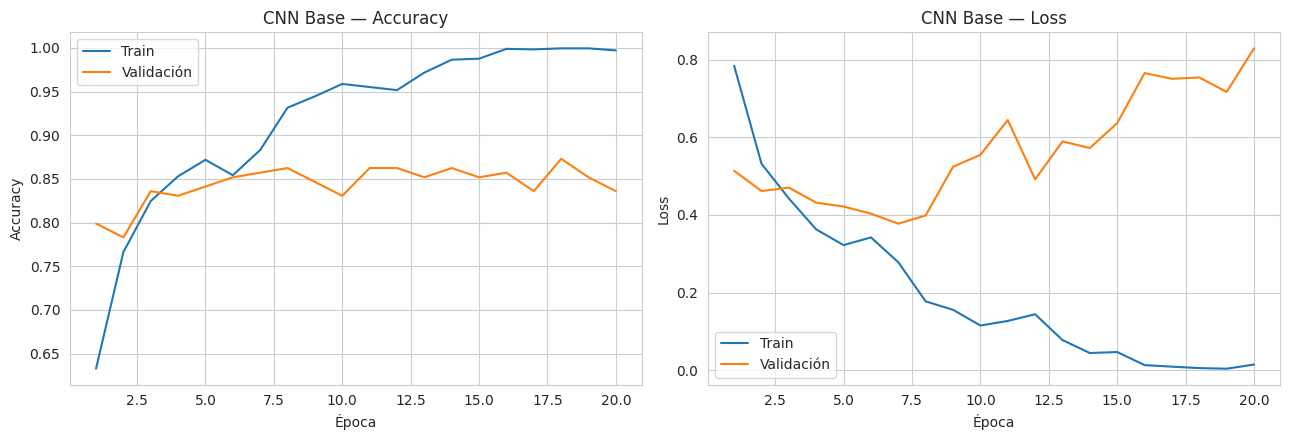

In [ ]:
def plot_history(history, titulo):
    h = history.history
    epochs = range(1, len(h['accuracy']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].plot(epochs, h['accuracy'], label='Train')
    axes[0].plot(epochs, h['val_accuracy'], label='Validación')
    axes[0].set_title(f'{titulo} — Accuracy')
    axes[0].set_xlabel('Época'); axes[0].set_ylabel('Accuracy'); axes[0].legend()
    axes[1].plot(epochs, h['loss'], label='Train')
    axes[1].plot(epochs, h['val_loss'], label='Validación')
    axes[1].set_title(f'{titulo} — Loss')
    axes[1].set_xlabel('Época'); axes[1].set_ylabel('Loss'); axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_history(hist_base, 'CNN Base')

### Diagnóstico de overfitting (CNN Base)

La CNN base presenta sobreajuste. La accuracy de entrenamiento aumenta de forma sostenida hasta 99.7 % en la época 20, mientras que la de validación se mantiene entre 83 % y 87 % (máximo de 87.3 % en la época 18 y 83.6 % en la última época). La brecha entre ambas es de 16.1 puntos porcentuales al final del entrenamiento y supera los 5 puntos desde la época 8. La loss de validación alcanza su mínimo en la época 7 (0.378) y desde entonces crece hasta 0.830, mientras que la loss de entrenamiento continúa descendiendo hasta 0.014. Este comportamiento indica que, a partir de ese punto, la red memoriza el conjunto de entrenamiento en lugar de aprender patrones que generalicen.

La arquitectura explica este resultado: el modelo tiene 4,288,067 parámetros, de los cuales 4,194,819 (97.8 %) pertenecen a las capas Dense posteriores a Flatten y solo 93,248 (2.2 %) a las capas convolucionales. Esa capa densa dispone de gran capacidad de memorización y el modelo no incorpora ninguna técnica de regularización.

## SECCIÓN D — CNN Mejorada (con regularización)

Para reducir el sobreajuste se incorporaron cinco técnicas:

- **Data Augmentation:** volteos horizontal y vertical, rotación de hasta ±10 % de vuelta y zoom de hasta 10 %. Son transformaciones coherentes con fotografías de campo, donde la hoja puede aparecer en cualquier orientación. No se aplicaron cambios de brillo, contraste ni color, porque el color de las lesiones es el síntoma que distingue cada enfermedad.
- **Batch Normalization** (momentum = 0.9), ubicada entre la convolución y la activación ReLU.
- **Dropout** progresivo (0.10, 0.15, 0.20 y 0.25) en los cuatro bloques convolucionales y 0.40 antes de la capa de salida.
- **Global Average Pooling** en lugar de Flatten.
- **Regularización L2** (1e-4) en las convoluciones y en la capa densa.

Callbacks: EarlyStopping (monitor = val_loss, patience = 8, activo desde la época 10, `restore_best_weights=True`) y ReduceLROnPlateau (monitor = val_loss, factor = 0.5, patience = 3).

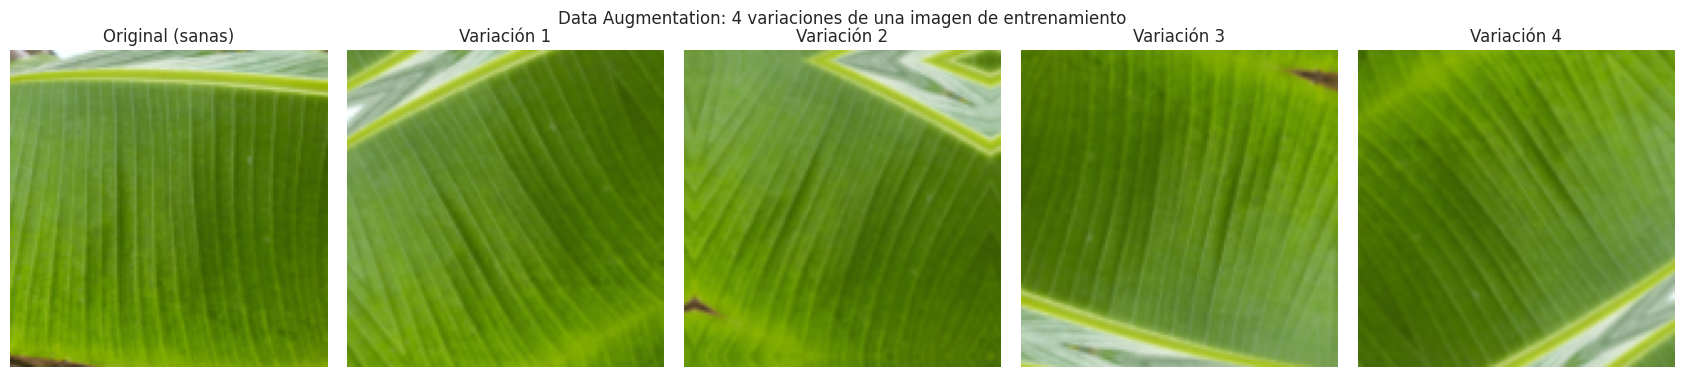

In [ ]:
# Aumento de datos: transformaciones geométricas suaves (solo se aplican durante el entrenamiento).
# Las hojas pueden aparecer en cualquier orientación en una foto de campo, por eso sirven los flips,
# las rotaciones y el zoom leves. NO se usan cambios fuertes de brillo/contraste/color porque el color
# de las lesiones (manchas amarillas/pardas/necróticas) es justamente el síntoma que distingue la enfermedad.
data_augmentation = keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.10),     # ± 10% de vuelta (±36°)
    layers.RandomZoom(0.10),
], name='data_augmentation')

# Visualizar 4 variaciones de una misma imagen
img = X_train[:1]
fig, axes = plt.subplots(1, 5, figsize=(17, 3.8))
axes[0].imshow(img[0]); axes[0].set_title(f'Original ({CLASS_NAMES[y_train[0]]})'); axes[0].axis('off')
for i in range(1, 5):
    aug = data_augmentation(img, training=True)
    axes[i].imshow(np.clip(aug[0].numpy(), 0, 1))
    axes[i].set_title(f'Variación {i}')
    axes[i].axis('off')
plt.suptitle('Data Augmentation: 4 variaciones de una imagen de entrenamiento')
plt.tight_layout()
plt.show()

In [ ]:
L2 = 1e-4

def conv_block(x, filters, dropout=0.25):
    # Conv (sin bias, porque BatchNorm ya aporta su propio desplazamiento) -> BN -> ReLU -> MaxPool -> Dropout
    x = layers.Conv2D(filters, 3, padding='same', use_bias=False,
                      kernel_regularizer=regularizers.l2(L2))(x)
    x = layers.BatchNormalization(momentum=0.9)(x)   # BN antes de la activación; momentum=0.9 (no 0.99) para que las estadísticas móviles
                                                     # se ajusten rápido con pocas iteraciones por época
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(dropout)(x)
    return x

def build_cnn_improved(optimizer='adam', name='cnn_mejorada'):
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = data_augmentation(inputs)            # solo activo en entrenamiento
    x = conv_block(x, 32, 0.10)
    x = conv_block(x, 64, 0.15)
    x = conv_block(x, 128, 0.20)
    x = conv_block(x, 256, 0.25)             # 4.º bloque: más capacidad para detalles finos
    x = layers.GlobalAveragePooling2D()(x)   # GAP en lugar de Flatten: menos parámetros
    x = layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(L2))(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)
    model = keras.Model(inputs, outputs, name=name)
    model.compile(optimizer=optimizer,
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

keras.utils.set_random_seed(SEED)
model_imp = build_cnn_improved()
model_imp.summary()
RESULTS['params_imp'] = model_imp.count_params()
print('\nTécnicas aplicadas: Data Augmentation + Batch Normalization + Dropout + Global Average Pooling + L2')
print(f"Parámetros: base = {RESULTS['params_base']:,} vs mejorada = {RESULTS['params_imp']:,}")

Model: "cnn_mejorada"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             

 Total params: 423,139 (1.61 MB)

 Trainable params: 422,179 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)


Técnicas aplicadas: Data Augmentation + Batch Normalization + Dropout + Global Average Pooling + L2
Parámetros: base = 4,288,067 vs mejorada = 423,139


In [ ]:
def make_callbacks():
    return [
        callbacks.EarlyStopping(monitor='val_loss', patience=8, start_from_epoch=10, restore_best_weights=True, verbose=1),
        callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1),
    ]

EPOCHS_IMP = 80   # máximo; EarlyStopping detiene antes si no mejora (se evalúa desde la época 10)
hist_imp = model_imp.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS_IMP,
    batch_size=BATCH_SIZE,
    callbacks=make_callbacks(),
    class_weight=CLASS_WEIGHT if USE_CLASS_WEIGHT else None,
    verbose=2)

Epoch 1/80
53/53 - 11s - 209ms/step - accuracy: 0.6322 - loss: 0.8553 - val_accuracy: 0.4339 - val_loss: 1.0281 - learning_rate: 0.0010
Epoch 2/80
53/53 - 3s - 55ms/step - accuracy: 0.6995 - loss: 0.7185 - val_accuracy: 0.6614 - val_loss: 0.6909 - learning_rate: 0.0010
Epoch 3/80
53/53 - 3s - 55ms/step - accuracy: 0.7332 - loss: 0.6506 - val_accuracy: 0.7513 - val_loss: 0.5419 - learning_rate: 0.0010
Epoch 4/80
53/53 - 3s - 54ms/step - accuracy: 0.7692 - loss: 0.6051 - val_accuracy: 0.8095 - val_loss: 0.4561 - learning_rate: 0.0010
Epoch 5/80
53/53 - 3s - 54ms/step - accuracy: 0.8093 - loss: 0.5265 - val_accuracy: 0.7249 - val_loss: 0.6329 - learning_rate: 0.0010
Epoch 6/80
53/53 - 3s - 55ms/step - accuracy: 0.8146 - loss: 0.4979 - val_accuracy: 0.6825 - val_loss: 0.7776 - learning_rate: 0.0010
Epoch 7/80

Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
53/53 - 3s - 55ms/step - accuracy: 0.8400 - loss: 0.4628 - val_accuracy: 0.7354 - val_loss: 0.6381 - learn

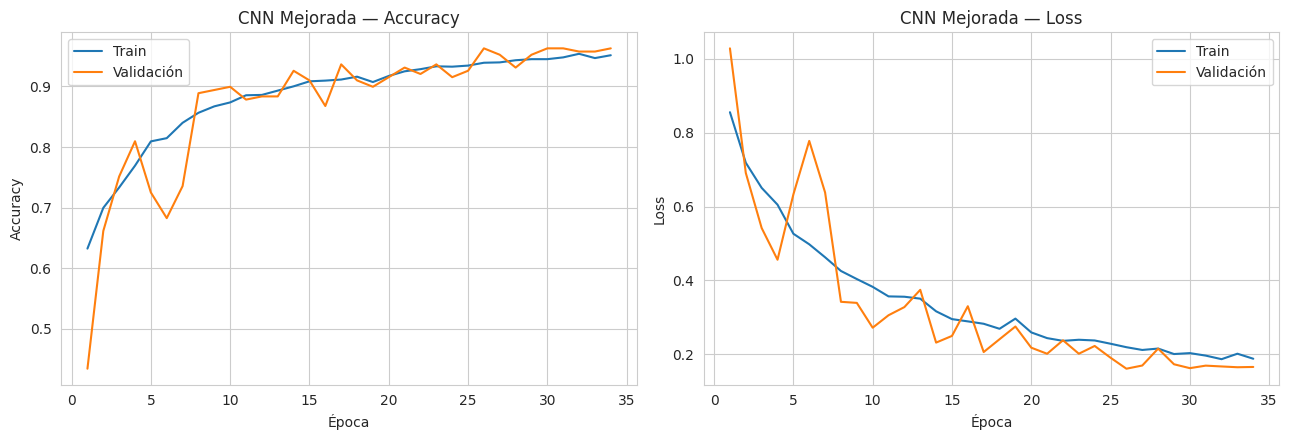

,CNN Base (última época),CNN Mejorada (mejor época)
Accuracy train,0.9970,0.9392
Accuracy val,0.8360,0.9630
Brecha train-val,0.1611,-0.0238
Mín. loss val,0.3776,0.1612
Épocas entrenadas,20,34
Parámetros,"4,288,067","423,139"


EarlyStopping restauró los pesos de la época 26 (de 34 entrenadas)


In [ ]:
plot_history(hist_imp, 'CNN Mejorada')

# Tabla comparativa CNN Base vs CNN Mejorada
hb, hi = hist_base.history, hist_imp.history
best_i = int(np.argmin(hi['val_loss']))           # época restaurada por EarlyStopping
imp_tr, imp_va = hi['accuracy'][best_i], hi['val_accuracy'][best_i]
base_tr, base_va = hb['accuracy'][-1], hb['val_accuracy'][-1]

comparacion = pd.DataFrame({
    'CNN Base (última época)': [base_tr, base_va, base_tr - base_va,
                                min(hb['val_loss']), len(hb['accuracy']), model_base.count_params()],
    'CNN Mejorada (mejor época)': [imp_tr, imp_va, imp_tr - imp_va,
                                   min(hi['val_loss']), len(hi['accuracy']), model_imp.count_params()],
}, index=['Accuracy train', 'Accuracy val', 'Brecha train-val', 'Mín. loss val', 'Épocas entrenadas', 'Parámetros'])
display(comparacion.style.format('{:.4f}', subset=pd.IndexSlice[['Accuracy train', 'Accuracy val', 'Brecha train-val', 'Mín. loss val'], :])
        .format('{:,.0f}', subset=pd.IndexSlice[['Épocas entrenadas', 'Parámetros'], :]))
print(f'EarlyStopping restauró los pesos de la época {best_i + 1} (de {len(hi["accuracy"])} entrenadas)')

### Comparación CNN Base vs Mejorada

La regularización mejoró el desempeño y eliminó el sobreajuste. La CNN mejorada alcanzó 96.3 % de accuracy de validación (época 26, restaurada por EarlyStopping) frente a 83.6 % de la CNN base en su última época (máximo de 87.3 %), una mejora de 12.7 puntos. La loss mínima de validación bajó de 0.378 a 0.161. La brecha entre entrenamiento y validación pasó de 16.1 a −2.4 puntos: la accuracy de entrenamiento de la red mejorada (93.9 %) es menor que la de validación porque se mide con Data Augmentation y Dropout activos, mientras que la validación se evalúa sin ellos. Además, el número de parámetros se redujo de 4,288,067 a 423,139 (aproximadamente 90 % menos) gracias a Global Average Pooling.

EarlyStopping detuvo el entrenamiento en la época 34 y restauró los pesos de la época 26. ReduceLROnPlateau redujo la tasa de aprendizaje en 6 ocasiones, de 1e-3 a 1.6e-5. Sin EarlyStopping, el entrenamiento habría continuado más allá del mejor punto de validación; sin ReduceLROnPlateau, la tasa de aprendizaje constante habría provocado mayores oscilaciones de la loss de validación cerca del mínimo.

**Nota de diseño.** En una versión inicial, con momentum = 0.99 en Batch Normalization y EarlyStopping activo desde la primera época, las estadísticas móviles de Batch Normalization no llegaban a ajustarse durante las primeras épocas (solo 53 iteraciones por época), la validación resultaba artificialmente baja y EarlyStopping restauraba los pesos de la época 1. Por ello se adoptaron momentum = 0.9 y `start_from_epoch=10`.

## SECCIÓN E — Comparación de Optimizadores

Se entrenó la arquitectura de la CNN mejorada con tres optimizadores: SGD (lr = 0.01, momentum = 0.9, Nesterov), Adam (lr = 0.001) y RMSprop (lr = 0.001). Para que la comparación sea equitativa se creó un modelo nuevo para cada optimizador, con la misma semilla y los mismos pesos iniciales, y se entrenó durante 30 épocas fijas sin callbacks.

In [ ]:
EPOCHS_OPT = 30   # número fijo de épocas, sin callbacks, para que la comparación sea justa

def get_optimizers():
    return {
        'SGD (lr=0.01, mom=0.9, Nesterov)': keras.optimizers.SGD(learning_rate=0.01, momentum=0.9, nesterov=True),
        'Adam (lr=0.001)': keras.optimizers.Adam(learning_rate=0.001),
        'RMSprop (lr=0.001)': keras.optimizers.RMSprop(learning_rate=0.001),
    }

opt_histories = {}
for name, opt in get_optimizers().items():
    print(f'\n===== Entrenando con {name} =====')
    keras.utils.set_random_seed(SEED)                          # mismas semillas y pesos iniciales para todos
    m = build_cnn_improved(optimizer=opt, name='cnn_opt')      # modelo NUEVO con la misma arquitectura
    opt_histories[name] = m.fit(X_train, y_train,
                                validation_data=(X_val, y_val),
                                epochs=EPOCHS_OPT, batch_size=BATCH_SIZE, verbose=2)
    del m
    keras.backend.clear_session()


===== Entrenando con SGD (lr=0.01, mom=0.9, Nesterov) =====
Epoch 1/30
53/53 - 6s - 111ms/step - accuracy: 0.6175 - loss: 0.8582 - val_accuracy: 0.4550 - val_loss: 0.9521
Epoch 2/30
53/53 - 3s - 54ms/step - accuracy: 0.6818 - loss: 0.7424 - val_accuracy: 0.4921 - val_loss: 0.9374
Epoch 3/30
53/53 - 3s - 53ms/step - accuracy: 0.7143 - loss: 0.7042 - val_accuracy: 0.5026 - val_loss: 0.9536
Epoch 4/30
53/53 - 3s - 53ms/step - accuracy: 0.7220 - loss: 0.6819 - val_accuracy: 0.6878 - val_loss: 0.6826
Epoch 5/30
53/53 - 3s - 53ms/step - accuracy: 0.7432 - loss: 0.6415 - val_accuracy: 0.6402 - val_loss: 0.7789
Epoch 6/30
53/53 - 3s - 53ms/step - accuracy: 0.7562 - loss: 0.6130 - val_accuracy: 0.7354 - val_loss: 0.5986
Epoch 7/30
53/53 - 3s - 53ms/step - accuracy: 0.7792 - loss: 0.5796 - val_accuracy: 0.7460 - val_loss: 0.5944
Epoch 8/30
53/53 - 3s - 54ms/step - accuracy: 0.7987 - loss: 0.5450 - val_accuracy: 0.7037 - val_loss: 0.6425
Epoch 9/30
53/53 - 3s - 54ms/step - accuracy: 0.7999 - los

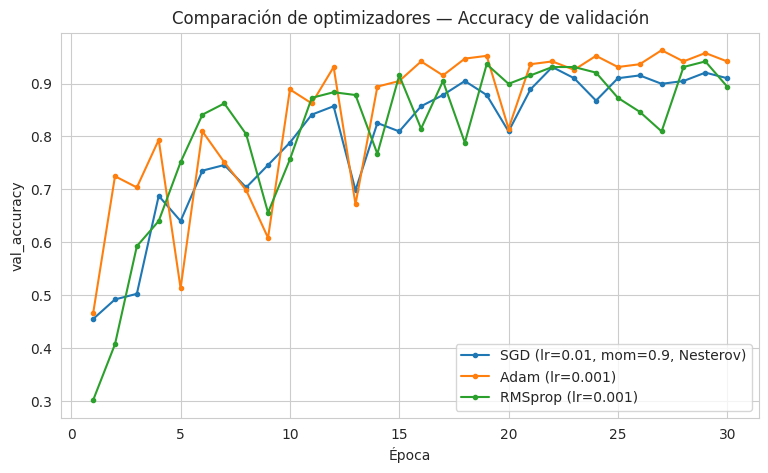

,Mejor val_acc,Época del mejor,Épocas hasta 91.5%,val_acc final,Desv. últimas 5 épocas
Optimizador,,,,,
"SGD (lr=0.01, mom=0.9, Nesterov)",0.9312,22,22,0.9101,0.0075
Adam (lr=0.001),0.9630,27,12,0.9418,0.0103
RMSprop (lr=0.001),0.9418,29,15,0.8942,0.0502


In [ ]:
plt.figure(figsize=(9, 5))
for name, hh in opt_histories.items():
    plt.plot(range(1, EPOCHS_OPT + 1), hh.history['val_accuracy'], marker='o', markersize=3, label=name)
plt.title('Comparación de optimizadores — Accuracy de validación')
plt.xlabel('Época')
plt.ylabel('val_accuracy')
plt.legend()
plt.show()

# Métricas de convergencia
best_global = max(max(hh.history['val_accuracy']) for hh in opt_histories.values())
target = 0.95 * best_global
filas = []
for name, hh in opt_histories.items():
    va = np.array(hh.history['val_accuracy'])
    first = next((i + 1 for i, v in enumerate(va) if v >= target), None)
    filas.append({'Optimizador': name, 'Mejor val_acc': va.max(), 'Época del mejor': int(va.argmax()) + 1,
                  f'Épocas hasta {target:.1%}': first if first else '—',
                  'val_acc final': va[-1], 'Desv. últimas 5 épocas': va[-5:].std()})
tabla_opt = pd.DataFrame(filas).set_index('Optimizador')
display(tabla_opt.round(4))

### Análisis de optimizadores

Adam obtuvo el mejor resultado y la convergencia más rápida. Alcanzó una val_accuracy máxima de 96.3 % (época 27) y fue el primero en superar el 91.5 % (95 % de su máximo) en la época 12, frente a la época 15 de RMSprop y la 22 de SGD. RMSprop llegó a 94.2 % (época 29) y SGD con Nesterov a 93.1 % (época 22).

En estabilidad, SGD presentó la menor desviación estándar de la val_accuracy en las últimas cinco épocas (0.008), seguido de Adam (0.010). RMSprop fue claramente inestable (desviación de 0.050), con caídas puntuales de la val_accuracy hasta 65.6 % (época 9) y un valor final de 89.4 %. Adam y RMSprop adaptan la tasa de aprendizaje de cada parámetro, lo que acelera el avance inicial; SGD avanza más lento al inicio, pero sus actualizaciones son más estables. Dado que el conjunto de validación contiene 189 imágenes (una imagen equivale a 0.5 puntos) y cada optimizador se entrenó una sola vez, las diferencias de uno o dos puntos deben interpretarse con cautela.

## SECCIÓN F — Evaluación rigurosa (sobre test, con la CNN Mejorada)

La evaluación final se realizó con la CNN mejorada (pesos de la época 26) sobre el conjunto de prueba de 471 imágenes, que no intervino en el entrenamiento ni en la selección de épocas.

In [ ]:
# Evaluación con la CNN Mejorada (pesos restaurados por EarlyStopping)
y_prob = model_imp.predict(X_test, batch_size=64, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
test_acc = accuracy_score(y_test, y_pred)
test_loss, _ = model_imp.evaluate(X_test, y_test, verbose=0)
RESULTS['test_acc'] = test_acc
print(f'Accuracy global en test: {test_acc:.4f} ({test_acc:.2%})   |   Loss en test: {test_loss:.4f}')
print(f'Imágenes de test: {len(y_test)}  |  Mal clasificadas: {(y_pred != y_test).sum()}')

Accuracy global en test: 0.9406 (94.06%)   |   Loss en test: 0.2055
Imágenes de test: 471  |  Mal clasificadas: 28


In [ ]:
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=3))
report = classification_report(y_test, y_pred, target_names=CLASS_NAMES, output_dict=True)
f1_por_clase = {c: report[c]['f1-score'] for c in CLASS_NAMES}
RESULTS['f1_por_clase'] = f1_por_clase
RESULTS['recall_por_clase'] = {c: report[c]['recall'] for c in CLASS_NAMES}
RESULTS['f1_macro'] = report['macro avg']['f1-score']

              precision    recall  f1-score   support

     cordana      0.960     0.883     0.920       163
       sanas      0.956     0.991     0.973       109
    sigatoka      0.918     0.960     0.939       199

    accuracy                          0.941       471
   macro avg      0.945     0.945     0.944       471
weighted avg      0.941     0.941     0.940       471



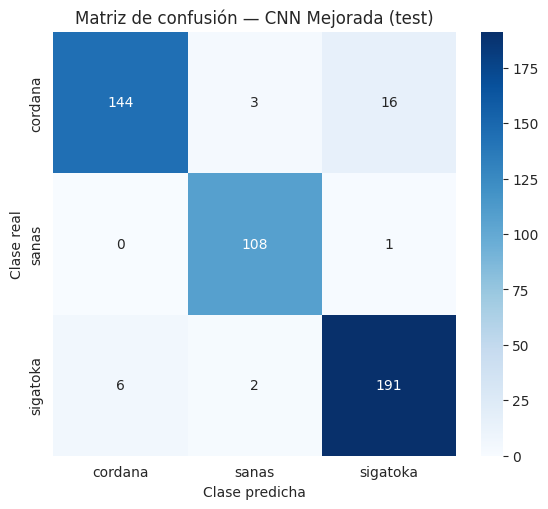

In [ ]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6.5, 5.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title('Matriz de confusión — CNN Mejorada (test)')
plt.xlabel('Clase predicha')
plt.ylabel('Clase real')
plt.show()

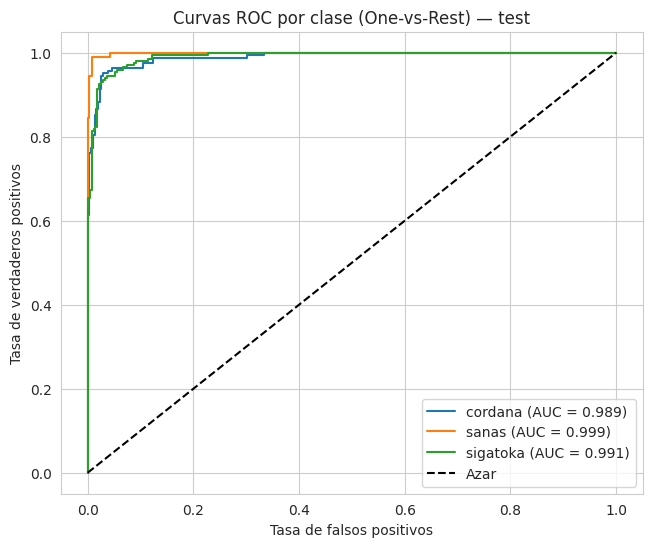

AUC por clase: {'cordana': np.float64(0.9891), 'sanas': np.float64(0.999), 'sigatoka': np.float64(0.9909)}
AUC macro (OvR): 0.9930


In [ ]:
y_test_bin = label_binarize(y_test, classes=np.arange(NUM_CLASSES))   # (N, 3) One-vs-Rest
plt.figure(figsize=(7.5, 6))
aucs = {}
for i, cname in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
    aucs[cname] = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{cname} (AUC = {aucs[cname]:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Azar')
plt.title('Curvas ROC por clase (One-vs-Rest) — test')
plt.xlabel('Tasa de falsos positivos')
plt.ylabel('Tasa de verdaderos positivos')
plt.legend(loc='lower right')
plt.show()
RESULTS['auc_por_clase'] = aucs
RESULTS['auc_macro'] = roc_auc_score(y_test, y_prob, multi_class='ovr', average='macro')
print('AUC por clase:', {k: round(v, 4) for k, v in aucs.items()})
print(f"AUC macro (OvR): {RESULTS['auc_macro']:.4f}")

### Interpretación de las métricas en el conjunto de prueba

La CNN mejorada obtuvo 94.06 % de accuracy global (443 aciertos y 28 errores sobre 471 imágenes) y un F1 macro de 0.944. Por clase, sanas presentó el mejor desempeño (precision 0.956, recall 0.991, F1 0.973), seguida de sigatoka (0.918, 0.960 y 0.939) y cordana (0.960, 0.883 y 0.920). Cordana tiene la precision más alta y el recall más bajo: cuando el modelo predice cordana casi siempre acierta, pero no reconoce cerca del 12 % de las hojas de esa clase.

Las curvas ROC One-vs-Rest confirman la alta capacidad discriminativa del modelo: AUC de 0.989 para cordana, 0.999 para sanas y 0.991 para sigatoka (AUC macro de 0.993). Un AUC cercano a 1 indica que las probabilidades asignadas a las imágenes de una clase son casi siempre mayores que las asignadas a las demás; el menor AUC de cordana es coherente con su menor recall.

In [ ]:
# Las 3 confusiones más frecuentes = mayores valores fuera de la diagonal de la matriz de confusión
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
orden = np.dstack(np.unravel_index(np.argsort(cm_off.ravel())[::-1], cm_off.shape))[0]
top_conf = [(CLASS_NAMES[r], CLASS_NAMES[c], int(cm_off[r, c])) for r, c in orden[:3]]
RESULTS['top_conf'] = top_conf

print('Las 3 confusiones más frecuentes (clase real → clase predicha):')
for k, (real, pred, n) in enumerate(top_conf, 1):
    total_real = int((y_test == CLASS_NAMES.index(real)).sum())
    print(f'  {k}. {real} → {pred}: {n} imágenes ({n / total_real:.1%} de las {total_real} imágenes reales de {real})')

Las 3 confusiones más frecuentes (clase real → clase predicha):
  1. cordana → sigatoka: 16 imágenes (9.8% de las 163 imágenes reales de cordana)
  2. sigatoka → cordana: 6 imágenes (3.0% de las 199 imágenes reales de sigatoka)
  3. cordana → sanas: 3 imágenes (1.8% de las 163 imágenes reales de cordana)


Imágenes mal clasificadas en test: 28


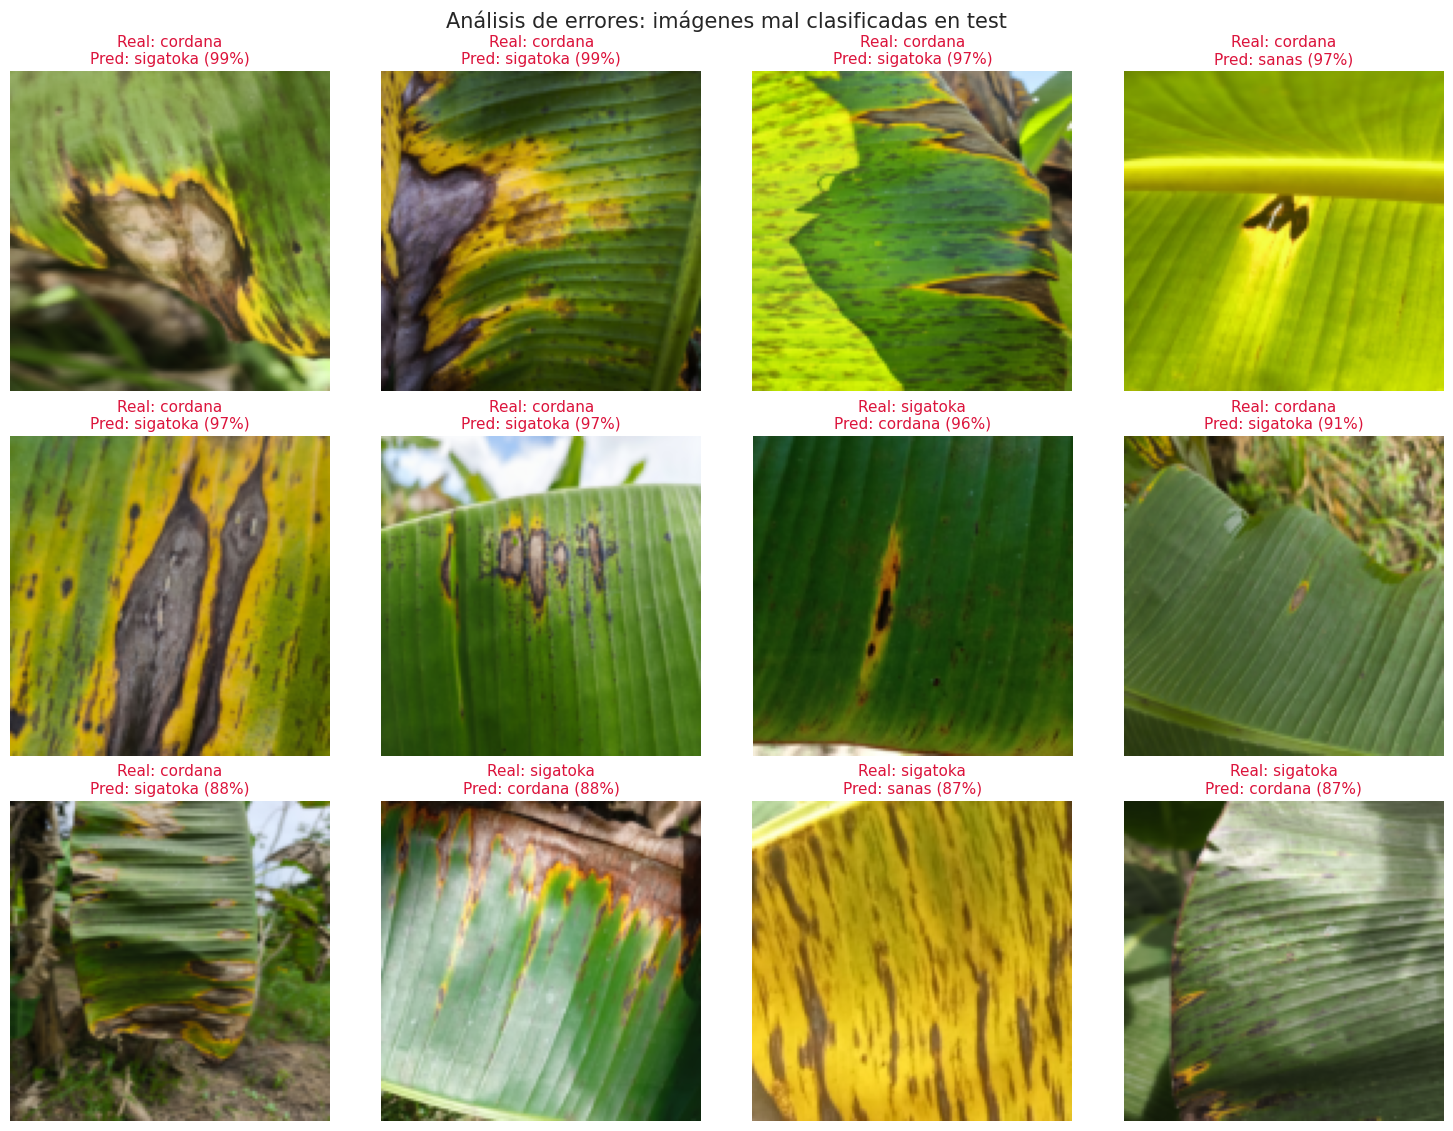

In [ ]:
wrong_idx = np.where(y_pred != y_test)[0]
print(f'Imágenes mal clasificadas en test: {len(wrong_idx)}')

# Se muestran las 12 con mayor confianza en la predicción errónea (los errores más "seguros" son los más informativos)
conf = y_prob[wrong_idx, y_pred[wrong_idx]]
show_idx = wrong_idx[np.argsort(conf)[::-1]][:12]

fig, axes = plt.subplots(3, 4, figsize=(15, 11.5))
for ax in axes.ravel():
    ax.axis('off')
for ax, idx in zip(axes.ravel(), show_idx):
    ax.imshow(X_test[idx])
    ax.set_title(f'Real: {CLASS_NAMES[y_test[idx]]}\nPred: {CLASS_NAMES[y_pred[idx]]} ({y_prob[idx, y_pred[idx]]:.0%})',
                 color='crimson', fontsize=11)
plt.suptitle('Análisis de errores: imágenes mal clasificadas en test', fontsize=15)
plt.tight_layout()
plt.show()
if len(wrong_idx) < 10:
    print('Nota: el modelo cometió menos de 10 errores en test, por lo que se muestran todos.')

### Explicación de las 3 confusiones más frecuentes

Las tres confusiones más frecuentes en el conjunto de prueba fueron:

1. **Cordana → Sigatoka:** 16 imágenes (9.8 % de las hojas de cordana).
2. **Sigatoka → Cordana:** 6 imágenes (3.0 % de las hojas de sigatoka).
3. **Cordana → Sanas:** 3 imágenes (1.8 % de las hojas de cordana).

Las dos primeras ocurren entre las dos enfermedades. Sigatoka y Cordana producen lesiones de aspecto similar (manchas y estrías pardas o necróticas con halo amarillento); en etapas tempranas, o cuando una misma hoja presenta lesiones de distinta edad, la diferencia depende de detalles finos de forma, tamaño y distribución de las manchas. Estos detalles se atenúan al reducir fotografías de aproximadamente 3000×4000 píxeles a 128×128 y se mezclan con fondos de vegetación, sombras y cambios de iluminación. La asimetría (16 frente a 6 errores) sugiere además un sesgo hacia la clase mayoritaria: sigatoka representa 42.3 % de las imágenes de entrenamiento y cordana 34.7 %, por lo que, ante lesiones ambiguas, el modelo tiende a asignar sigatoka.

La tercera confusión corresponde a hojas con lesiones pequeñas o poco contrastadas que, tras el redimensionado, resultan difíciles de distinguir de una hoja sana. Las confusiones restantes son marginales (sigatoka → sanas: 2 imágenes; sanas → sigatoka: 1 imagen) y confirman que la clase sanas es la mejor diferenciada (recall de 0.991).

In [ ]:
# Cuadro resumen de las métricas del notebook
hb, hi = hist_base.history, hist_imp.history
bi = int(np.argmin(hi['val_loss']))
lr_hist = hi.get('learning_rate', [])
n_red = sum(1 for a, b in zip(lr_hist, lr_hist[1:]) if b < a)

L = []
L.append('### Cuadro resumen de métricas')
L.append('| Modelo | Acc. train | Acc. val | Brecha (pts) | Mín. val_loss | Épocas | Parámetros |')
L.append('|---|---|---|---|---|---|---|')
L.append(f"| CNN Base (última época) | {hb['accuracy'][-1]:.1%} | {hb['val_accuracy'][-1]:.1%} | {(hb['accuracy'][-1] - hb['val_accuracy'][-1]) * 100:.1f} | {min(hb['val_loss']):.3f} | {len(hb['accuracy'])} | {model_base.count_params():,} |")
L.append(f"| CNN Mejorada (época {bi + 1}) | {hi['accuracy'][bi]:.1%} | {hi['val_accuracy'][bi]:.1%} | {(hi['accuracy'][bi] - hi['val_accuracy'][bi]) * 100:.1f} | {min(hi['val_loss']):.3f} | {len(hi['accuracy'])} | {model_imp.count_params():,} |")
L.append(f'\nReducciones de learning rate (ReduceLROnPlateau) en la CNN mejorada: **{n_red}**.')
L.append('\n| Optimizador | Mejor val_acc | Época del mejor | val_acc final |')
L.append('|---|---|---|---|')
for n, r in tabla_opt.iterrows():
    L.append(f"| {n} | {r['Mejor val_acc']:.1%} | {int(r['Época del mejor'])} | {r['val_acc final']:.1%} |")
L.append(f"\n**Test (CNN Mejorada):** accuracy = **{test_acc:.2%}**, F1 macro = **{report['macro avg']['f1-score']:.3f}**, AUC macro OvR = **{RESULTS['auc_macro']:.3f}**")
L.append('\n| Clase | Precision | Recall | F1 | AUC |')
L.append('|---|---|---|---|---|')
for c in CLASS_NAMES:
    L.append(f"| {c} | {report[c]['precision']:.3f} | {report[c]['recall']:.3f} | {report[c]['f1-score']:.3f} | {RESULTS['auc_por_clase'][c]:.3f} |")
L.append('\n**Top 3 confusiones (real → predicha):** ' + '; '.join(f'{a} → {b} ({n})' for a, b, n in top_conf))
display(Markdown('\n'.join(L)))

### Cuadro resumen de métricas
| Modelo | Acc. train | Acc. val | Brecha (pts) | Mín. val_loss | Épocas | Parámetros |
|---|---|---|---|---|---|---|
| CNN Base (última época) | 99.7% | 83.6% | 16.1 | 0.378 | 20 | 4,288,067 |
| CNN Mejorada (época 26) | 93.9% | 96.3% | -2.4 | 0.161 | 34 | 423,139 |

Reducciones de learning rate (ReduceLROnPlateau) en la CNN mejorada: **6**.

| Optimizador | Mejor val_acc | Época del mejor | val_acc final |
|---|---|---|---|
| SGD (lr=0.01, mom=0.9, Nesterov) | 93.1% | 22 | 91.0% |
| Adam (lr=0.001) | 96.3% | 27 | 94.2% |
| RMSprop (lr=0.001) | 94.2% | 29 | 89.4% |

**Test (CNN Mejorada):** accuracy = **94.06%**, F1 macro = **0.944**, AUC macro OvR = **0.993**

| Clase | Precision | Recall | F1 | AUC |
|---|---|---|---|---|
| cordana | 0.960 | 0.883 | 0.920 | 0.989 |
| sanas | 0.956 | 0.991 | 0.973 | 0.999 |
| sigatoka | 0.918 | 0.960 | 0.939 | 0.991 |

**Top 3 confusiones (real → predicha):** cordana → sigatoka (16); sigatoka → cordana (6); cordana → sanas (3)

## SECCIÓN G — Conclusiones

**1. Resumen de resultados.** La CNN mejorada alcanzó 94.06 % de accuracy en el conjunto de prueba, con F1 macro de 0.944 y AUC macro One-vs-Rest de 0.993. La mejor clase fue sanas (F1 = 0.973; recall = 0.991; AUC = 0.999) y la de menor desempeño fue cordana (F1 = 0.920; recall = 0.883; AUC = 0.989). La accuracy en prueba es ligeramente inferior a la de validación (96.3 %), resultado esperable porque la época final se seleccionó con el conjunto de validación, que es pequeño (189 imágenes). En la comparación de optimizadores, Adam obtuvo la mayor val_accuracy (96.3 %) y la convergencia más rápida, seguido de RMSprop (94.2 %) y SGD con Nesterov (93.1 %).

**2. Impacto de la regularización.** La CNN base sobreajustó: 99.7 % de accuracy en entrenamiento frente a 83.6 % en validación (brecha de 16.1 puntos) y loss de validación creciente desde la época 7. Con Data Augmentation, Batch Normalization, Dropout, Global Average Pooling y regularización L2, la accuracy de validación subió a 96.3 %, la brecha desapareció (−2.4 puntos) y los parámetros se redujeron de 4,288,067 a 423,139. EarlyStopping y ReduceLROnPlateau permitieron seleccionar el mejor punto del entrenamiento (época 26) y refinar progresivamente la tasa de aprendizaje.

**3. Confusiones más frecuentes y posibles causas.** Las confusiones principales fueron cordana → sigatoka (16 imágenes), sigatoka → cordana (6) y cordana → sanas (3). Las causas más probables son la similitud visual entre las lesiones de ambas enfermedades, la pérdida de detalle fino al reducir las imágenes a 128×128, la variabilidad de las fotografías de campo (luz, sombras, fondo) y un sesgo leve hacia la clase mayoritaria.

**4. Lecciones aprendidas por el grupo.**
- Con clases desbalanceadas, la accuracy global no es suficiente: es necesario revisar recall y F1 por clase y la matriz de confusión.
- La partición estratificada mantiene la proporción de clases en entrenamiento, validación y prueba.
- Las transformaciones de Data Augmentation deben elegirse según el dominio: volteos, rotaciones y zoom leves son adecuados; los cambios fuertes de color o brillo podrían eliminar el síntoma que distingue la enfermedad.
- Batch Normalization requiere un `momentum` adecuado cuando hay pocas iteraciones por época, y EarlyStopping no debe poder restaurar pesos de las primeras épocas, cuando el modelo aún no se estabiliza.
- Para comparar optimizadores es necesario reiniciar los pesos y fijar las semillas.
- Global Average Pooling y Batch Normalization producen una red 10 veces más pequeña y con menos sobreajuste que Flatten con una capa Dense grande.

**5. Limitaciones y posibles mejoras.** El dataset está desbalanceado y proviene de cuatro sitios de la región San Martín, por lo que el modelo podría no generalizar a otras regiones, variedades, cámaras o condiciones de iluminación. Se utilizó una única partición de los datos y una única ejecución por configuración, y el conjunto de validación es pequeño. La reducción a 128×128 píxeles implica pérdida de detalle de las lesiones. Como mejoras se proponen: mayor resolución de entrada (160–224 px), `class_weight` o sobremuestreo de la clase minoritaria, validación cruzada estratificada, visualización con Grad-CAM para verificar que el modelo se concentra en las lesiones y ampliación del dataset con imágenes de otras zonas y etapas de la enfermedad.

## SECCIÓN H (Anexo) — Transfer learning con MobileNetV2

Como complemento se evaluó transfer learning con MobileNetV2 preentrenada en ImageNet, un modelo liviano (2,261,827 parámetros) adecuado para imágenes pequeñas y pocos datos. El entrenamiento se realizó en dos etapas: (1) entrenamiento de la capa de clasificación con la base convolucional congelada (3,843 parámetros entrenables) y (2) ajuste fino de las últimas 40 capas con una tasa de aprendizaje de 1e-5. La evaluación se realizó sobre el mismo conjunto de prueba. La Sección F corresponde exclusivamente a la CNN mejorada, según la consigna.

In [ ]:
# Etapa 1: MobileNetV2 preentrenada en ImageNet, congelada; solo se entrena la cabeza de clasificación
base_tl = keras.applications.MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights='imagenet')
base_tl.trainable = False

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = data_augmentation(inputs)
x = layers.Rescaling(scale=2.0, offset=-1.0)(x)     # MobileNetV2 espera entradas en [-1, 1]; nuestras imágenes están en [0, 1]
x = base_tl(x, training=False)                      # BatchNorm interna en modo inferencia
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)
model_tl = keras.Model(inputs, outputs, name='mobilenetv2_tl')
model_tl.compile(optimizer=keras.optimizers.Adam(1e-3),
                 loss='sparse_categorical_crossentropy', metrics=['accuracy'])
print(f'Parámetros totales: {model_tl.count_params():,} | entrenables (etapa 1): '
      f'{sum(int(np.prod(w.shape)) for w in model_tl.trainable_weights):,}')

def make_tl_callbacks():
    return [callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
            callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-7, verbose=1)]

h1 = model_tl.fit(X_train, y_train, validation_data=(X_val, y_val),
                  epochs=20, batch_size=BATCH_SIZE, callbacks=make_tl_callbacks(), verbose=2)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Parámetros totales: 2,261,827 | entrenables (etapa 1): 3,843
Epoch 1/20
53/53 - 9s - 173ms/step - accuracy: 0.6942 - loss: 0.7603 - val_accuracy: 0.9048 - val_loss: 0.2686 - learning_rate: 0.0010
Epoch 2/20
53/53 - 2s - 31ms/step - accuracy: 0.8571 - loss: 0.3609 - val_accuracy: 0.9259 - val_loss: 0.2009 - learning_rate: 0.0010
Epoch 3/20
53/53 - 2s - 34ms/step - accuracy: 0.8808 - loss: 0.3243 - val_accuracy: 0.9206 - val_loss: 0.1887 - learning_rate: 0.0010
Epoch 4/20
53/53 - 2s - 32ms/step - accuracy: 0.8902 - loss: 0.2845 - val_accuracy: 0.9418 - val_loss: 0.1694 - learning_rate: 0.0010
Epoch 5/20
53/53 - 2s - 31ms/step - accuracy: 0.9097 - loss: 0.2536 - val_accuracy: 0.9418 - val_loss: 0.1626 - learning_rate: 0.0010
Epoch 6/20
53/53 - 2s - 30ms/step - accuracy: 0.9061 - loss: 0.2511 - val_accuracy: 0.9365 - val_loss: 0.1719 - learning_rate: 0.0010
Epoch 7/20
53/53 - 2s - 30ms/step - accuracy: 0.9109 - loss: 0.2356 - val_accuracy: 0

Epoch 1/20
53/53 - 17s - 320ms/step - accuracy: 0.8294 - loss: 0.4175 - val_accuracy: 0.9259 - val_loss: 0.1864 - learning_rate: 1.0000e-05
Epoch 2/20
53/53 - 2s - 45ms/step - accuracy: 0.8678 - loss: 0.3495 - val_accuracy: 0.9153 - val_loss: 0.2161 - learning_rate: 1.0000e-05
Epoch 3/20
53/53 - 3s - 48ms/step - accuracy: 0.8802 - loss: 0.3156 - val_accuracy: 0.9101 - val_loss: 0.2477 - learning_rate: 1.0000e-05
Epoch 4/20

Epoch 4: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
53/53 - 2s - 45ms/step - accuracy: 0.8955 - loss: 0.2812 - val_accuracy: 0.8995 - val_loss: 0.2899 - learning_rate: 1.0000e-05
Epoch 5/20
53/53 - 2s - 45ms/step - accuracy: 0.9002 - loss: 0.2549 - val_accuracy: 0.8889 - val_loss: 0.3107 - learning_rate: 5.0000e-06
Epoch 6/20
53/53 - 2s - 45ms/step - accuracy: 0.9061 - loss: 0.2596 - val_accuracy: 0.8889 - val_loss: 0.3274 - learning_rate: 5.0000e-06
Epoch 6: early stopping
Restoring model weights from the end of the best epoch: 1.


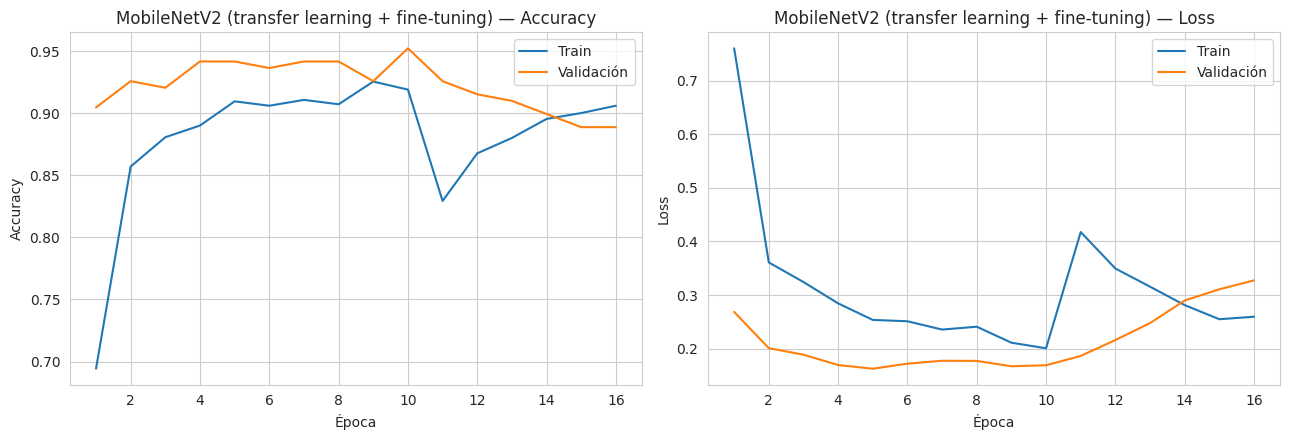

In [ ]:
# Etapa 2 (fine-tuning): se descongelan las últimas 40 capas de MobileNetV2 con una tasa de aprendizaje muy baja
base_tl.trainable = True
for layer in base_tl.layers[:-40]:
    layer.trainable = False
model_tl.compile(optimizer=keras.optimizers.Adam(1e-5),
                 loss='sparse_categorical_crossentropy', metrics=['accuracy'])
h2 = model_tl.fit(X_train, y_train, validation_data=(X_val, y_val),
                  epochs=20, batch_size=BATCH_SIZE, callbacks=make_tl_callbacks(), verbose=2)

# Historia combinada de las dos etapas para graficar
class _Hist: pass
h_tl = _Hist()
h_tl.history = {k: h1.history[k] + h2.history[k] for k in ['accuracy', 'val_accuracy', 'loss', 'val_loss']}
plot_history(h_tl, 'MobileNetV2 (transfer learning + fine-tuning)')

Accuracy en test (MobileNetV2): 0.9299 (92.99%)

              precision    recall  f1-score   support

     cordana      0.959     0.853     0.903       163
       sanas      0.900     0.991     0.943       109
    sigatoka      0.927     0.960     0.943       199

    accuracy                          0.930       471
   macro avg      0.929     0.934     0.930       471
weighted avg      0.932     0.930     0.929       471



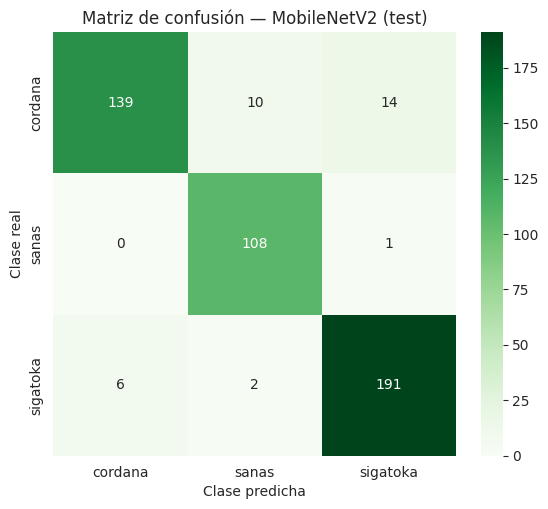

,CNN Mejorada (propia),MobileNetV2 (transfer learning)
Accuracy test,0.941,0.930
F1 macro,0.944,0.930
AUC macro OvR,0.993,0.989
Recall cordana,0.883,0.853
Recall sanas,0.991,0.991
Recall sigatoka,0.960,0.960


In [ ]:
y_prob_tl = model_tl.predict(X_test, batch_size=64, verbose=0)
y_pred_tl = np.argmax(y_prob_tl, axis=1)
acc_tl = accuracy_score(y_test, y_pred_tl)
print(f'Accuracy en test (MobileNetV2): {acc_tl:.4f} ({acc_tl:.2%})\n')
print(classification_report(y_test, y_pred_tl, target_names=CLASS_NAMES, digits=3))

cm_tl = confusion_matrix(y_test, y_pred_tl)
plt.figure(figsize=(6.5, 5.5))
sns.heatmap(cm_tl, annot=True, fmt='d', cmap='Greens', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title('Matriz de confusión — MobileNetV2 (test)')
plt.xlabel('Clase predicha')
plt.ylabel('Clase real')
plt.show()

rep_tl = classification_report(y_test, y_pred_tl, target_names=CLASS_NAMES, output_dict=True)
auc_tl = roc_auc_score(y_test, y_prob_tl, multi_class='ovr', average='macro')
comp = pd.DataFrame({
    'CNN Mejorada (propia)': [test_acc, report['macro avg']['f1-score'], RESULTS['auc_macro']] + [report[c]['recall'] for c in CLASS_NAMES],
    'MobileNetV2 (transfer learning)': [acc_tl, rep_tl['macro avg']['f1-score'], auc_tl] + [rep_tl[c]['recall'] for c in CLASS_NAMES],
}, index=['Accuracy test', 'F1 macro', 'AUC macro OvR'] + [f'Recall {c}' for c in CLASS_NAMES])
display(comp.style.format('{:.3f}'))

### Comparación CNN propia vs MobileNetV2

La CNN mejorada obtuvo mejor desempeño que MobileNetV2 en el conjunto de prueba: 94.06 % frente a 92.99 % de accuracy, F1 macro de 0.944 frente a 0.930 y AUC macro de 0.993 frente a 0.989. La diferencia se concentra en la clase cordana (recall de 0.883 frente a 0.853) y en la precision de sanas (0.956 frente a 0.900); el recall de sanas (0.991) y de sigatoka (0.960) es igual en ambos modelos.

En la primera etapa, MobileNetV2 alcanzó 94.2 % de val_accuracy en la época 5, lo que muestra la ventaja de reutilizar filtros preentrenados. Sin embargo, el ajuste fino de la segunda etapa no mejoró la validación: la loss aumentó de 0.186 a 0.327 en seis épocas y EarlyStopping restauró los pesos de la primera. Con aproximadamente 1,700 imágenes de entrenamiento y entradas de 128×128, la CNN diseñada para este problema, con aumento de datos y regularización, resultó competitiva frente al modelo preentrenado. Una mayor resolución de entrada (160–224 px) queda como mejora futura.